<a href="https://www.kaggle.com/code/maryammoghaddasbayat/aipolicy-29oktober?scriptVersionId=364695460" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Stakeholder Power Dynamics and Governance Asymmetries in AI Policy
**Team MK** – Maryam Moghaddas Bayat & Kelvin Obour Coleman
Data: AIPolicyTracker Open Data (policies, obligations, jurisdictions, implementation)
#
Pipeline: load -> merge -> rule-based coding (two independent coders) -> inter-coder agreement
-> RQ1 (rights vs recognition) -> RQ2 (binding vs voluntary) -> RQ3 (regression) -> RQ4 (burden)
#
HOW TO USE ON KAGGLE: add the four CSVs as a Kaggle Dataset, attach it to the notebook,
then run all cells. Paths are discovered automatically.

In [1]:
import os, re, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.metrics import cohen_kappa_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 50, "display.max_colwidth", 80)
OUT = "/kaggle/working" if os.path.exists("/kaggle/working") else "."
SEED = 42
rng = np.random.default_rng(SEED)

try:
    from IPython.display import display, Markdown
except Exception:                       # plain-python fallback
    display = print
    Markdown = str
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight", "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
SAVED = {"tables": [], "figures": []}

def show(obj, title, fname=None, index=True):
    """Display a table in the notebook (so it is visible on GitHub) and save it as CSV."""
    display(Markdown(f"**{title}**"))
    display(obj)
    if fname:
        obj.to_csv(f"{OUT}/{fname}.csv", index=index)
        SAVED["tables"].append(f"{fname}.csv")

def savefig(name, title=None):
    """Save the current figure as PDF (vector) + PNG in the working folder, then show it inline."""
    fig = plt.gcf()
    fig.savefig(f"{OUT}/{name}.pdf")
    fig.savefig(f"{OUT}/{name}.png", dpi=200)
    SAVED["figures"] += [f"{name}.pdf", f"{name}.png"]
    plt.show()

## 1. Load data

In [2]:
# Your dataset/folder in the Kaggle notebook is called "AIpolicy_29OK".
# Kaggle may mount it under a slightly different spelling (e.g. aipolicy-29ok), so we search
# /kaggle/input case-insensitively, preferring any folder that looks like it.
DATA_FOLDER = "AIpolicy_29OK"
ROOTS = ["/kaggle/input", "."]

def find(name):
    hits = []
    for root in ROOTS:
        for dirpath, _, files in os.walk(root):
            for f in files:
                if f.lower().endswith(".csv") and name.lower() in f.lower():
                    hits.append(os.path.join(dirpath, f))
    if not hits:
        raise FileNotFoundError(
            f"No CSV containing '{name}' found. Check the files under /kaggle/input (run: !ls -R /kaggle/input).")
    key = re.sub(r"[^a-z0-9]", "", DATA_FOLDER.lower())
    hits.sort(key=lambda p: 0 if key in re.sub(r"[^a-z0-9]", "", p.lower()) else 1)
    print(f"{name:15s} -> {hits[0]}")
    return hits[0]

pol = pd.read_csv(find("policies"))
obl = pd.read_csv(find("obligations"))
jur = pd.read_csv(find("jurisdictions"))
imp = pd.read_csv(find("implementation"))
sizes = pd.DataFrame({n: d.shape for n, d in [("policies", pol), ("obligations", obl),
                      ("jurisdictions", jur), ("implementation", imp)]}, index=["rows", "columns"]).T
show(sizes, "Table 1. Dataset sizes", "t01_dataset_sizes")

policies        -> /kaggle/input/datasets/maryammoghaddasbayat/aipolicy-29ok/aipolicytracker-policies.csv
obligations     -> /kaggle/input/datasets/maryammoghaddasbayat/aipolicy-29ok/aipolicytracker-obligations.csv
jurisdictions   -> /kaggle/input/datasets/maryammoghaddasbayat/aipolicy-29ok/aipolicytracker-jurisdictions.csv
implementation  -> /kaggle/input/datasets/maryammoghaddasbayat/aipolicy-29ok/aipolicytracker-implementation.csv


**Table 1. Dataset sizes**

,rows,columns
policies,244,25
obligations,117,18
jurisdictions,249,20
implementation,8,27


## 2. Clean, merge and build analysis variables
* Document format and jurisdictional tier are the controls named in RQ3.
* Obligations are linked to policies via `obligations.policy == policies.slug`.

Policies with jurisdiction match: 1.0


**Table 2. Corpus composition (binding status, document format, jurisdictional tier)**

n_policies  share
law_type non-binding (soft law)         163  0.668
         binding (hard law)              81  0.332
format   strategy                        99  0.406
         statute                         76  0.311
         soft_guidance                   35  0.143
         policy                          30  0.123
         consultation                     4  0.016
tier     country                        164  0.672
         state                           67  0.275
         supranational                   13  0.053

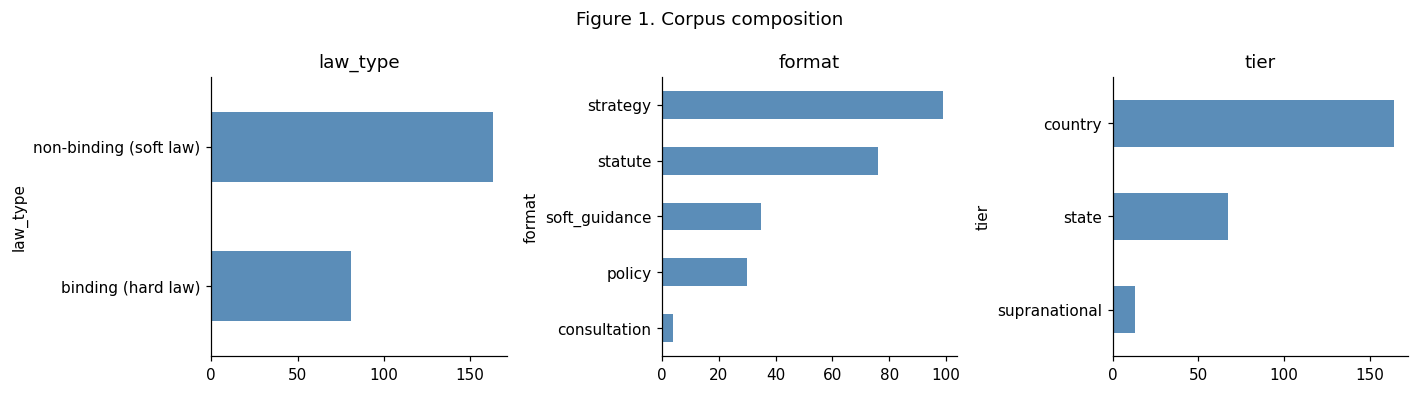

In [3]:
for c in ["adopted_on", "published_on", "in_force_on", "applies_from"]:
    pol[c] = pd.to_datetime(pol[c], errors="coerce")
obl["applies_from"] = pd.to_datetime(obl["applies_from"], errors="coerce")

jt = jur[["slug", "jurisdiction_type", "region", "subregion"]].rename(columns={"slug": "jurisdiction"})
pol = pol.merge(jt, on="jurisdiction", how="left")
print("Policies with jurisdiction match:", pol["jurisdiction_type"].notna().mean().round(3))

FORMAT_MAP = {
    "act": "statute", "regulation": "statute", "bill": "statute", "executive_order": "statute",
    "strategy": "strategy", "policy": "policy",
    "guidance": "soft_guidance", "framework": "soft_guidance", "standard": "soft_guidance",
    "code_of_practice": "soft_guidance", "consultation": "consultation",
}
pol["format"] = pol["instrument_type"].map(FORMAT_MAP).fillna("other")
# collapse to 3 levels for regression (strategy alone has zero 'strong remedy' cases -> quasi-separation)
pol["format3"] = pol["format"].replace({"strategy": "strategy_policy", "policy": "strategy_policy",
                                        "consultation": "strategy_policy"})
pol["tier"] = pol["jurisdiction_type"].replace({"territory": "state", "region": "state"})  # collapse tiny cells
pol["law_type"] = np.where(pol["is_binding"], "binding (hard law)", "non-binding (soft law)")

# policy-level obligation text
obl["obl_text"] = (obl["title"].fillna("") + ". " + obl["summary"].fillna("") + ". " + obl["practical_action"].fillna(""))
obl_agg = (obl.groupby("policy")
              .agg(n_obligations=("slug", "count"), obl_text=("obl_text", " ".join))
              .reset_index().rename(columns={"policy": "slug"}))
pol = pol.merge(obl_agg, on="slug", how="left")
pol["n_obligations"] = pol["n_obligations"].fillna(0).astype(int)
pol["text"] = (pol["title"].fillna("") + ". " + pol["summary_plain"].fillna("") + ". "
               + pol["who_it_applies_to"].fillna("") + ". " + pol["obl_text"].fillna(""))
desc = pd.concat({c: pol[c].value_counts() for c in ["law_type", "format", "tier"]}, axis=0).rename("n_policies").to_frame()
desc["share"] = (desc["n_policies"] / len(pol)).round(3)
show(desc, "Table 2. Corpus composition (binding status, document format, jurisdictional tier)", "t02_corpus_composition")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, c in zip(axes, ["law_type", "format", "tier"]):
    pol[c].value_counts().plot(kind="barh", ax=ax, color="#5b8db8"); ax.set_title(c); ax.invert_yaxis()
fig.suptitle("Figure 1. Corpus composition"); plt.tight_layout()
savefig("fig01_corpus_composition")

## 3. Standardised coding manual (two independent rule-based coders)
#
**Unit of coding:** policy document (text = title + plain summary + applicability + linked obligations).
#
**Variables**
1. *Stakeholder groups recognised* (binary per group): consumers/individuals, workers, children,
   vulnerable groups, civil society/public.
2. *Recognition type per group*: 0 = not mentioned, 1 = **passive recognition** (mentioned only),
   2 = **active/enforceable** (mentioned in same sentence as a right, remedy, redress or sanction term).
3. *Remedy strength* (ordinal 0-3): 0 none; 1 symbolic/aspirational; 2 procedural (notice, appeal, contest,
   human review, complaint); 3 enforceable (penalty, fine, damages, private right of action, enforcement authority).
#
Coder A and Coder B use **different, independently written lexicons and decision rules**
(B additionally uses modal-verb logic: must/shall vs should/may).
A human double-coding sample is exported at the end so the automated coders can be validated.

In [4]:
STAKEHOLDERS_A = {
    "consumers_individuals": r"\b(consumers?|individuals?|data subjects?|natural persons?|citizens?|users?|residents?|members of the public|people)\b",
    "workers": r"\b(workers?|employees?|employment|job applicants?|candidates?|labou?r)\b",
    "children": r"\b(children|child|minors?|youth|young people)\b",
    "vulnerable_groups": r"\b(vulnerable|disabilit\w+|elderly|patients?|marginali[sz]ed|discriminat\w+|bias\w*|protected (class|characteristic)s?)\b",
    "civil_society": r"\b(civil society|public interest|affected (persons|people|communities)|communit(y|ies)|society|stakeholders?|public consultation)\b",
}
STAKEHOLDERS_B = {
    "consumers_individuals": r"(consumer|individual|data subject|natural person|citizen|end[- ]user|resident|the public|persons? affected)",
    "workers": r"(worker|employee|employ|hiring|recruit|applicant)",
    "children": r"(child|minor|juvenile|youth)",
    "vulnerable_groups": r"(vulnerab|disabilit|elder|patient|health|marginali|discriminat|bias|fundamental rights?|equity|equal)",
    "civil_society": r"(civil society|public interest|communit|affected|society|stakeholder|participat|consult)",
}
GROUPS = list(STAKEHOLDERS_A)

# Remedy lexicons (ordinal tiers)
REM_A = {
    3: r"\b(penalt\w+|fines?|fined|sanctions?|damages|compensation|private right of action|injunct\w+|enforce(d|ment)?|liab\w+|prosecut\w+|revok\w+|prohibit\w+|banned?)\b",
    2: r"\b(appeal\w*|contest\w*|challenge\w*|complain\w*|redress|right to (explanation|object|access|erasure|opt[- ]out)|opt[- ]out|human (review|oversight|intervention)|notice|notif\w+|disclos\w+|grievance|impact assessment|audit\w*)\b",
    1: r"\b(principles?|encourag\w+|promot\w+|voluntar\w+|should|aspir\w+|ethic\w+|trustworthy|responsible|guidance|best practices?)\b",
}
REM_B = {
    3: r"(penalt|fine[sd]?\b|sanction|damage|compensat|right of action|injunct|enforc|liabilit|criminal|civil penalt|revocation|ban\b)",
    2: r"(appeal|contest|challeng|complaint|redress|explanation|opt-?out|human review|human oversight|human control|intervention|notif|inform(ed)? of|transparency|disclos|grievance|assessment|audit|record)",
    1: r"(principle|encourag|promot|voluntar|ethic|trust|responsible|recommend|best practice|support|foster)",
}
BINDING_MODAL = re.compile(r"\b(must|shall|required to|is required|are required|obliged|mandatory|prohibited from)\b", re.I)
SOFT_MODAL = re.compile(r"\b(should|may|encourag\w+|recommend\w*|voluntar\w+|aims? to|seeks? to)\b", re.I)


def sentences(t):
    return [s.strip() for s in re.split(r"(?<=[.!?;])\s+", str(t)) if len(s.strip()) > 3]


def tier_hit(sent, lex):
    for k in (3, 2, 1):
        if re.search(lex[k], sent, re.I):
            return k
    return 0


def code_A(text):
    """Coder A: sentence co-occurrence of stakeholder term + remedy tier term."""
    res = {g: 0 for g in GROUPS}
    best = 0
    for s in sentences(text):
        t = tier_hit(s, REM_A)
        best = max(best, t)
        for g, rx in STAKEHOLDERS_A.items():
            if re.search(rx, s, re.I):
                res[g] = max(res[g], 1 if t < 2 else 2)
    return res, best


def code_B(text):
    """Coder B: independent lexicon + modal logic (soft modals cap remedy strength at 'symbolic')."""
    res = {g: 0 for g in GROUPS}
    best = 0
    for s in sentences(text):
        t = tier_hit(s, REM_B)
        if SOFT_MODAL.search(s) and not BINDING_MODAL.search(s):
            t = min(t, 1)
        best = max(best, t)
        for g, rx in STAKEHOLDERS_B.items():
            if re.search(rx, s, re.I):
                res[g] = max(res[g], 1 if t < 2 else 2)
    return res, best


def apply_coder(fn, tag):
    rows = [fn(t) for t in pol["text"]]
    g = pd.DataFrame([r[0] for r in rows]).add_prefix(f"{tag}_grp_")
    g[f"{tag}_remedy"] = [r[1] for r in rows]
    return g

coded = pd.concat([apply_coder(code_A, "A"), apply_coder(code_B, "B")], axis=1)
pol = pd.concat([pol.reset_index(drop=True), coded], axis=1)
for tag in "AB":
    cols = [f"{tag}_grp_{g}" for g in GROUPS]
    pol[f"{tag}_n_groups"] = (pol[cols] > 0).sum(axis=1)
    pol[f"{tag}_inclusion"] = (pol[f"{tag}_n_groups"] > 0).astype(int)
    pol[f"{tag}_strong_remedy"] = (pol[f"{tag}_remedy"] >= 2).astype(int)

## 4. Inter-coder agreement
Cohen's kappa (nominal), quadratic-weighted kappa (ordinal), with bootstrap 95% CIs.

**Table 3. Inter-coder agreement (Coder A vs Coder B)**

,variable,kappa,ci_low,ci_high,pct_agreement
0,recognition level: consumers_individuals,0.449,0.319,0.575,0.820
1,recognition level: workers,0.845,0.691,0.955,0.980
2,recognition level: children,0.927,0.748,1.000,0.996
3,recognition level: vulnerable_groups,0.433,0.301,0.552,0.824
4,recognition level: civil_society,0.753,0.631,0.858,0.943
5,stakeholder inclusion (any),0.515,0.418,0.622,0.758
6,remedy strength (0-3),0.691,0.594,0.779,0.725
7,strong remedy (>=2),0.630,0.532,0.726,0.828


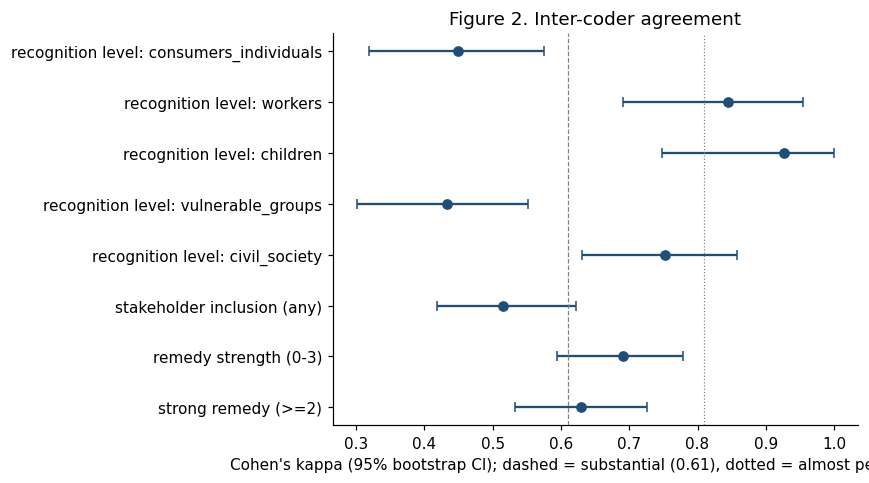

In [5]:
def boot_kappa(a, b, weights=None, n=1000):
    a, b = np.asarray(a), np.asarray(b)
    ks = []
    for _ in range(n):
        i = rng.integers(0, len(a), len(a))
        if len(set(a[i])) < 2 and len(set(b[i])) < 2:
            continue
        ks.append(cohen_kappa_score(a[i], b[i], weights=weights))
    return np.percentile(ks, [2.5, 97.5])

rows = []
for g in GROUPS:
    a, b = pol[f"A_grp_{g}"], pol[f"B_grp_{g}"]
    k = cohen_kappa_score(a, b); lo, hi = boot_kappa(a, b)
    rows.append([f"recognition level: {g}", k, lo, hi, (a == b).mean()])
for name, ca, cb, w in [("stakeholder inclusion (any)", "A_inclusion", "B_inclusion", None),
                        ("remedy strength (0-3)", "A_remedy", "B_remedy", "quadratic"),
                        ("strong remedy (>=2)", "A_strong_remedy", "B_strong_remedy", None)]:
    k = cohen_kappa_score(pol[ca], pol[cb], weights=w); lo, hi = boot_kappa(pol[ca], pol[cb], w)
    rows.append([name, k, lo, hi, (pol[ca] == pol[cb]).mean()])
kappa_tbl = pd.DataFrame(rows, columns=["variable", "kappa", "ci_low", "ci_high", "pct_agreement"]).round(3)
show(kappa_tbl, "Table 3. Inter-coder agreement (Coder A vs Coder B)", "t03_intercoder_agreement", index=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
yy = np.arange(len(kappa_tbl))
ax.errorbar(kappa_tbl["kappa"], yy, xerr=[kappa_tbl["kappa"] - kappa_tbl["ci_low"], kappa_tbl["ci_high"] - kappa_tbl["kappa"]],
            fmt="o", color="#1f4e79", capsize=3)
ax.axvline(0.61, ls="--", c="grey", lw=0.8); ax.axvline(0.81, ls=":", c="grey", lw=0.8)
ax.set_yticks(yy); ax.set_yticklabels(kappa_tbl["variable"]); ax.invert_yaxis()
ax.set_xlabel("Cohen's kappa (95% bootstrap CI); dashed = substantial (0.61), dotted = almost perfect (0.81)")
ax.set_title("Figure 2. Inter-coder agreement"); plt.tight_layout()
savefig("fig02_intercoder_agreement")

# Reconciled consensus codes used in the analysis: where coders disagree on remedy, take the LOWER (conservative) value
pol["remedy"] = np.minimum(pol["A_remedy"], pol["B_remedy"])
pol["strong_remedy"] = (pol["remedy"] >= 2).astype(int)
for g in GROUPS:
    pol[f"grp_{g}"] = np.minimum(pol[f"A_grp_{g}"], pol[f"B_grp_{g}"])   # recognised only if BOTH coders agree it is present
pol["n_groups"] = (pol[[f"grp_{g}" for g in GROUPS]] > 0).sum(axis=1)
pol["inclusion"] = (pol["n_groups"] > 0).astype(int)

## 5. RQ1 – Enforceable rights vs symbolic recognition by stakeholder group

**Table 4. RQ1 - Recognition type by stakeholder group (number of policy documents)**

,not_recognised,passive_recognition,active_enforceable,pct_active_of_recognised
stakeholder_group,,,,
consumers_individuals,217,14,13,0.481
workers,229,8,7,0.467
children,237,5,2,0.286
vulnerable_groups,222,11,11,0.500
civil_society,216,23,5,0.179


**Table 5. RQ1 - Share of documents granting ACTIVE/enforceable treatment, by binding status**

law_type,binding (hard law),non-binding (soft law)
group,,
children,0.025,0.000
civil_society,0.037,0.012
consumers_individuals,0.123,0.018
vulnerable_groups,0.099,0.018
workers,0.086,0.000


**Table 5b. RQ1 - Share of documents with PASSIVE recognition only, by binding status**

law_type,binding (hard law),non-binding (soft law)
group,,
children,0.062,0.000
civil_society,0.012,0.135
consumers_individuals,0.074,0.049
vulnerable_groups,0.049,0.043
workers,0.074,0.012


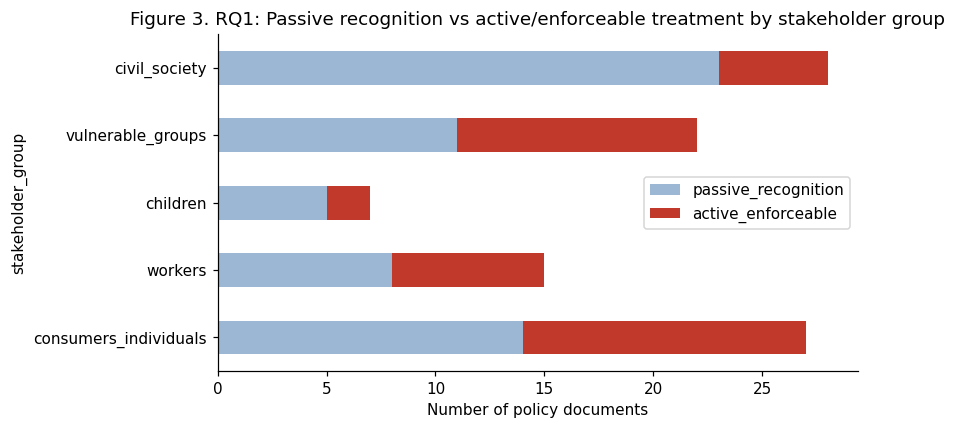

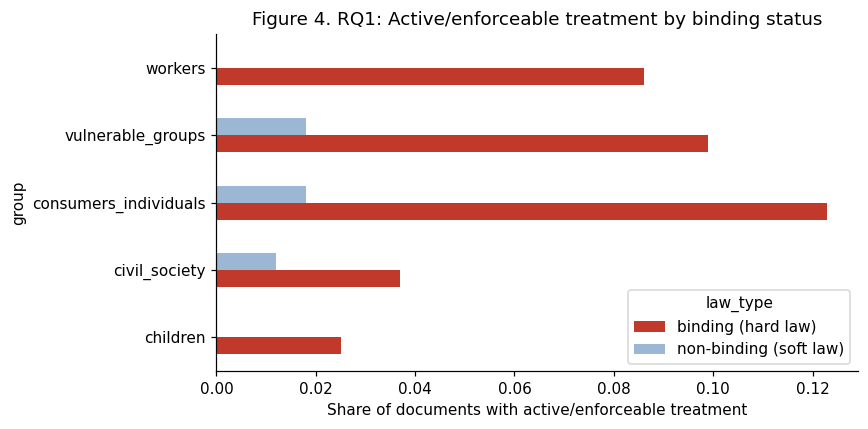

In [6]:
rq1 = []
for g in GROUPS:
    v = pol[f"grp_{g}"]
    rq1.append({"stakeholder_group": g, "not_recognised": (v == 0).sum(),
                "passive_recognition": (v == 1).sum(), "active_enforceable": (v == 2).sum()})
rq1 = pd.DataFrame(rq1).set_index("stakeholder_group")
rq1["pct_active_of_recognised"] = (rq1["active_enforceable"] / (rq1["passive_recognition"] + rq1["active_enforceable"])).round(3)
show(rq1, "Table 4. RQ1 - Recognition type by stakeholder group (number of policy documents)", "t04_rq1_group_recognition")

# by binding status
rq1b = []
for lt, d in pol.groupby("law_type"):
    for g in GROUPS:
        v = d[f"grp_{g}"]
        rq1b.append({"law_type": lt, "group": g, "n": len(d), "passive": (v == 1).mean(), "active": (v == 2).mean()})
rq1b = pd.DataFrame(rq1b)
piv = rq1b.pivot(index="group", columns="law_type", values="active").round(3)
show(piv, "Table 5. RQ1 - Share of documents granting ACTIVE/enforceable treatment, by binding status", "t05_rq1_active_by_binding")
rq1b_full = rq1b.pivot(index="group", columns="law_type", values="passive").round(3)
show(rq1b_full, "Table 5b. RQ1 - Share of documents with PASSIVE recognition only, by binding status", "t05b_rq1_passive_by_binding")

ax = rq1[["passive_recognition", "active_enforceable"]].plot(kind="barh", stacked=True, figsize=(8, 4), color=["#9bb7d4", "#c0392b"])
ax.set_title("Figure 3. RQ1: Passive recognition vs active/enforceable treatment by stakeholder group")
ax.set_xlabel("Number of policy documents"); plt.tight_layout()
savefig("fig03_rq1_stakeholders")

ax = piv.plot(kind="barh", figsize=(8, 4), color=["#c0392b", "#9bb7d4"])
ax.set_xlabel("Share of documents with active/enforceable treatment")
ax.set_title("Figure 4. RQ1: Active/enforceable treatment by binding status"); plt.tight_layout()
savefig("fig04_rq1_active_by_binding")

## 6. RQ2 – Binding vs voluntary accountability structures
Stratified cross-tabulations (binding vs non-binding), overall and within document format / tier.

**Table 6. RQ2 - remedy by law type (row shares; chi2 test p = 2.213e-17)**

remedy,0,1,2,3
law_type,,,,
binding (hard law),0.198,0.173,0.432,0.198
non-binding (soft law),0.288,0.613,0.080,0.018


**Table 6. RQ2 - inclusion by law type (row shares; Fisher test p = 0.000544)**

inclusion,0,1
law_type,,
binding (hard law),0.556,0.444
non-binding (soft law),0.779,0.221


**Table 6. RQ2 - strong_remedy by law type (row shares; Fisher test p = 7.566e-18)**

strong_remedy,0,1
law_type,,
binding (hard law),0.370,0.630
non-binding (soft law),0.902,0.098


**Table 7. RQ2 - Obligation categories, column share within binding (True) / non-binding (False) (chi2 = 21.51, p = 0.310; small expected counts, interpret cautiously)**

is_binding,False,True
category,,
accuracy_robustness_security,0.00,0.031
ai_literacy,0.00,0.010
conformity_assessment,0.00,0.010
copyright_training_data,0.00,0.010
data_governance,0.05,0.021
governance_accountability,0.40,0.113
human_oversight,0.15,0.062
impact_assessment,0.10,0.052
incident_handling,0.00,0.072


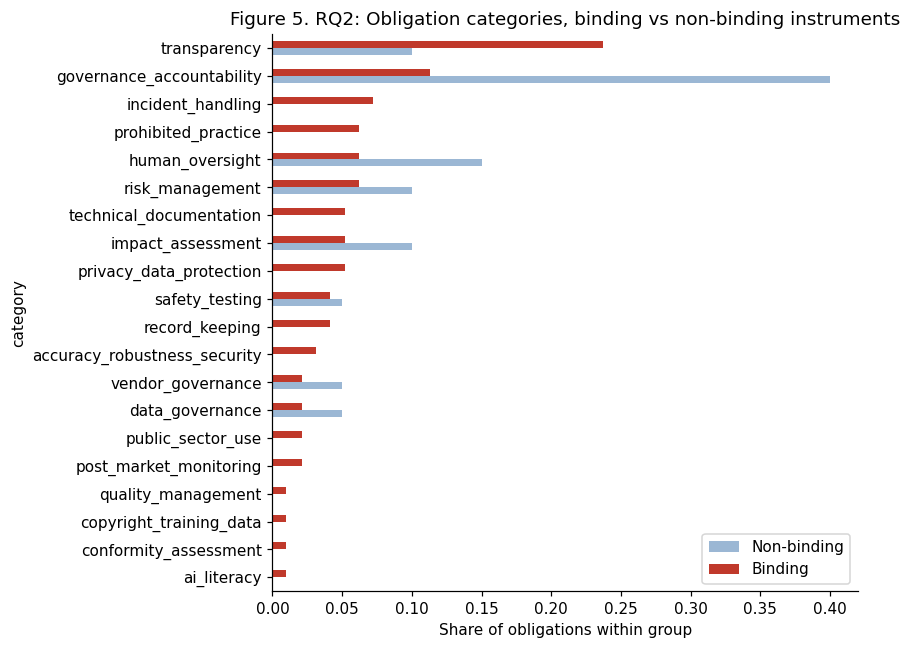

**Table 8. RQ2 - Share of obligations that are oversight/accountability mechanisms (index: is_binding)**

,share_accountability_mechanisms,n_accountability,n_obligations
is_binding,,,
False,0.750,15,20
True,0.495,48,97


**Table 9. RQ2 - Stratified summary by document format and binding status**

n  mean_remedy  pct_inclusion  mean_obligations
format        law_type                                                                
consultation  non-binding (soft law)   4        1.250          0.250             0.000
policy        binding (hard law)       6        0.500          0.000             0.000
              non-binding (soft law)  24        0.875          0.167             0.250
soft_guidance binding (hard law)       4        0.750          0.500             0.500
              non-binding (soft law)  31        1.226          0.516             0.516
statute       binding (hard law)      71        1.775          0.479             1.296
              non-binding (soft law)   5        1.600          0.600             0.000
strategy      non-binding (soft law)  99        0.636          0.121             0.010

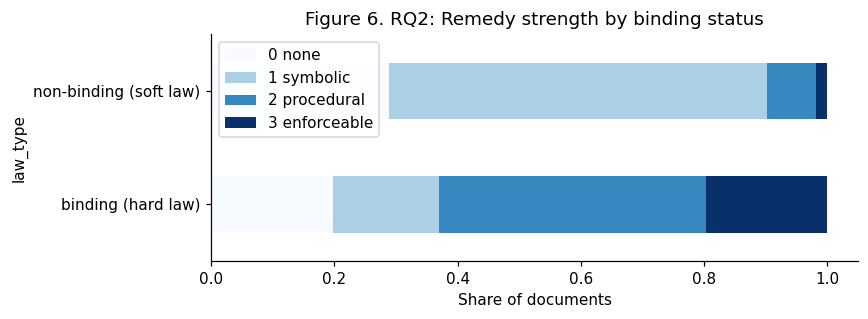

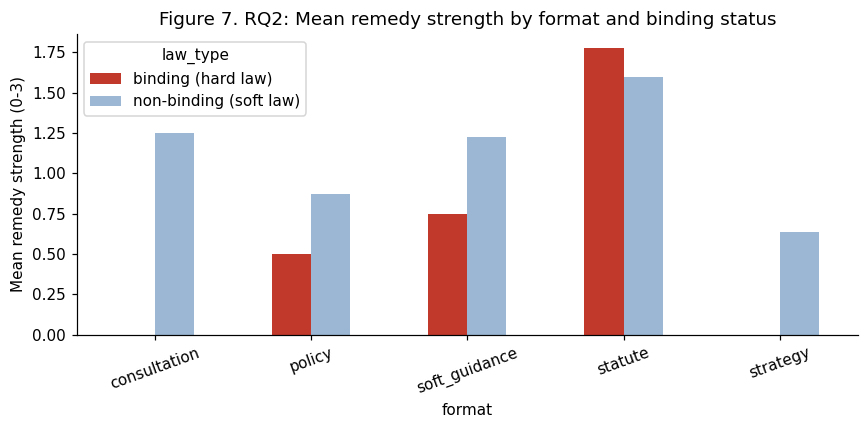

In [7]:
def xtab_test(df, row, col):
    ct = pd.crosstab(df[row], df[col])
    if ct.shape == (2, 2):
        _, p = stats.fisher_exact(ct)
        test = "Fisher"
    else:
        _, p, _, _ = stats.chi2_contingency(ct); test = "chi2"
    return ct, test, p

for col in ["remedy", "inclusion", "strong_remedy"]:
    ct, test, p = xtab_test(pol, "law_type", col)
    show(pd.crosstab(pol["law_type"], pol[col], normalize="index").round(3),
         f"Table 6. RQ2 - {col} by law type (row shares; {test} test p = {p:.4g})", f"t06_rq2_{col}_by_law_type")

# obligation-level accountability categories
obl_j = obl.merge(pol[["slug", "law_type", "format", "tier"]].rename(columns={"slug": "policy"}), on="policy", how="left")
obl_j["law_type"] = obl_j["law_type"].fillna(pd.Series(np.where(obl_j["is_binding"], "binding (hard law)", "non-binding (soft law)"), index=obl_j.index))
cat_ct = pd.crosstab(obl_j["category"], obl_j["is_binding"])
cat_share = (cat_ct / cat_ct.sum()).round(3)
chi2, p, _, _ = stats.chi2_contingency(cat_ct)
show(cat_share, f"Table 7. RQ2 - Obligation categories, column share within binding (True) / non-binding (False) "
                f"(chi2 = {chi2:.2f}, p = {p:.3f}; small expected counts, interpret cautiously)", "t07_rq2_obligation_categories_by_binding")
cat_share.sort_values(True).plot(kind="barh", figsize=(8, 6), color=["#9bb7d4", "#c0392b"])
plt.xlabel("Share of obligations within group"); plt.legend(["Non-binding", "Binding"])
plt.title("Figure 5. RQ2: Obligation categories, binding vs non-binding instruments"); plt.tight_layout()
savefig("fig05_rq2_obligation_categories")

ACCOUNT = ["governance_accountability", "human_oversight", "risk_management", "impact_assessment",
           "incident_handling", "record_keeping", "post_market_monitoring", "conformity_assessment",
           "quality_management", "technical_documentation"]
obl_j["accountability_cat"] = obl_j["category"].isin(ACCOUNT)
acc = obl_j.groupby("is_binding")["accountability_cat"].agg(["mean", "sum", "count"]).round(3)
acc.columns = ["share_accountability_mechanisms", "n_accountability", "n_obligations"]
show(acc, "Table 8. RQ2 - Share of obligations that are oversight/accountability mechanisms (index: is_binding)", "t08_rq2_accountability_share")

# stratified: binding vs not within format
strat = (pol.groupby(["format", "law_type"]).agg(n=("slug", "count"), mean_remedy=("remedy", "mean"),
                                                 pct_inclusion=("inclusion", "mean"),
                                                 mean_obligations=("n_obligations", "mean")).round(3))
show(strat, "Table 9. RQ2 - Stratified summary by document format and binding status", "t09_rq2_stratified_summary")

rem_dist = pd.crosstab(pol["law_type"], pol["remedy"], normalize="index")
rem_dist.columns = ["0 none", "1 symbolic", "2 procedural", "3 enforceable"][:rem_dist.shape[1]]
rem_dist.plot(kind="barh", stacked=True, figsize=(8, 3), colormap="Blues")
plt.xlabel("Share of documents"); plt.title("Figure 6. RQ2: Remedy strength by binding status"); plt.tight_layout()
savefig("fig06_rq2_remedy_by_binding")

fig, ax = plt.subplots(figsize=(8, 4))
strat.reset_index().pivot(index="format", columns="law_type", values="mean_remedy").plot(kind="bar", ax=ax, color=["#c0392b", "#9bb7d4"])
ax.set_ylabel("Mean remedy strength (0-3)"); ax.set_title("Figure 7. RQ2: Mean remedy strength by format and binding status")
plt.xticks(rotation=20); plt.tight_layout()
savefig("fig07_rq2_stratified_remedy")

## 7. RQ3 – Does stakeholder inclusion independently predict remedy strength?
Outcome: strong remedy (remedy >= 2). Predictor: stakeholder inclusion (and number of groups).
Controls: document format, jurisdictional tier. Log-odds (logit) + ordered logit robustness.
Robust (HC1) standard errors; small cells are collapsed to limit separation.

**N in regression models = 244**

**Table 10. RQ3 - Logit model 1 (outcome: strong remedy >= 2; HC1 robust SE)**

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:          strong_remedy   No. Observations:                  244
Model:                          Logit   Df Residuals:                      238
Method:                           MLE   Df Model:                            5
Date:                Sun, 01 Nov 2026   Pseudo R-squ.:                  0.3998
Time:                        23:38:16   Log-Likelihood:                -86.082
converged:                       True   LL-Null:                       -143.42
Covariance Type:                  HC1   LLR p-value:                 4.222e-23
=================================================================================================
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
Intercept                        -1.5171      0.489     -3.103      0.002      -2.475      -0.559
C(format3)[T.statute]             2.0996      0.517      4.063      0.000       1.087       3.113
C(format3)[T.strategy_policy]    -1.8654      0.644     -2.895      0.004      -3.128      -0.602
C(tier)[T.state]                 -0.3932      0.463     -0.850      0.396      -1.300       0.514
C(tier)[T.supranational]          0.6752      0.706      0.956      0.339      -0.709       2.059
inclusion                         0.8963      0.435      2.063      0.039       0.045       1.748
=================================================================================================
"""

**Table 11. RQ3 - Adjusted effect of stakeholder inclusion on strong remedy (odds ratios)**

,coef,odds_ratio,OR_ci_low,OR_ci_high,p
Model 1: inclusion (binary),0.8963,2.4505,1.0457,5.7426,0.0391
Model 2: number of groups,0.8414,2.3195,1.3560,3.9678,0.0021


**Table 12. RQ3 - Model fit and likelihood-ratio test for stakeholder inclusion**

,McFadden pseudo-R2,log-likelihood,LR chi2 (inclusion),LR p-value
controls only,0.3822,-88.6095,NaN,NaN
controls + inclusion,0.3998,-86.0823,5.054,0.02456


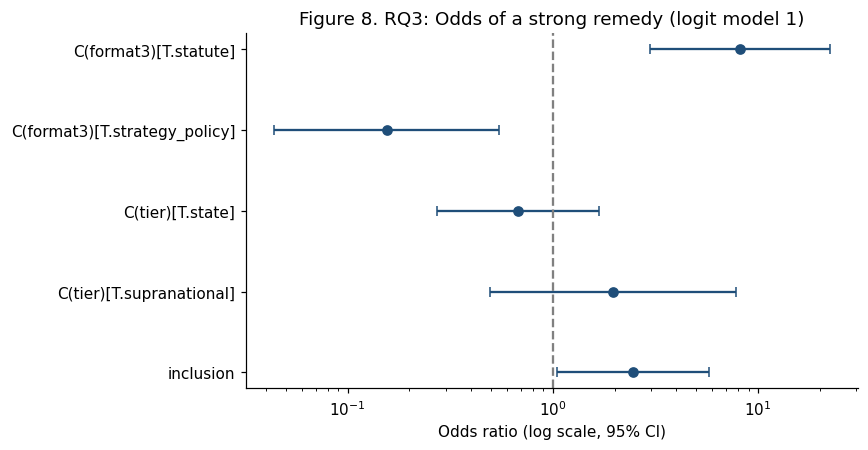

**Table 13. RQ3 - Ordered logit robustness (remedy 0-3)**

,coef,odds_ratio,p
inclusion,0.7083,2.0305,0.0195


**Table 14. RQ3 - Sensitivity: binding instruments only**

,odds_ratio,p,N
inclusion (binding only),2.4413,0.0744,81


**Table 15. RQ3 - Predicted probability of strong remedy by format and stakeholder inclusion (0 = no, 1 = yes)**

inclusion,0,1
format3,,
soft_guidance,0.195,0.368
statute,0.594,0.780
strategy_policy,0.032,0.075


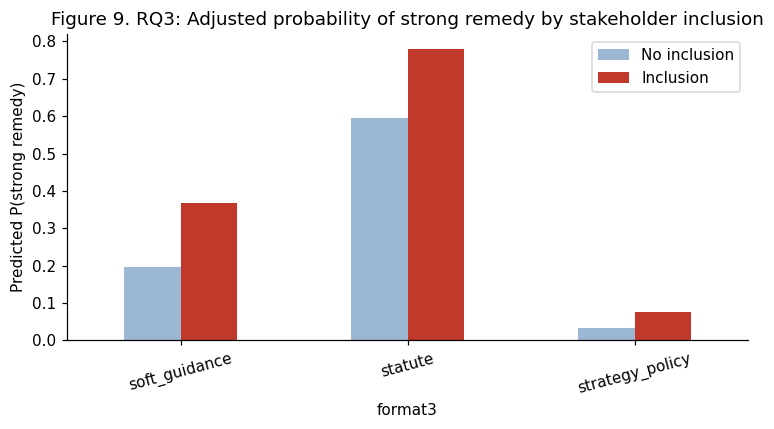

In [8]:
d = pol.dropna(subset=["format3", "tier"]).copy()
d["format3"] = d["format3"].astype("category")
d["tier"] = d["tier"].astype("category")
display(Markdown(f"**N in regression models = {len(d)}**"))

def fit_logit(formula, data):
    try:
        return smf.logit(formula, data).fit(disp=0, cov_type="HC1")
    except Exception as e:
        print("Logit failed (", e, ") -> using L2-penalised fit")
        return smf.logit(formula, data).fit_regularized(disp=0, alpha=0.5)

m0 = fit_logit("strong_remedy ~ C(format3) + C(tier)", d)
m1 = fit_logit("strong_remedy ~ inclusion + C(format3) + C(tier)", d)
m2 = fit_logit("strong_remedy ~ n_groups + C(format3) + C(tier)", d)
display(Markdown("**Table 10. RQ3 - Logit model 1 (outcome: strong remedy >= 2; HC1 robust SE)**"))
try:
    display(m1.summary())
    coef_tbl = pd.DataFrame({"coef": m1.params, "std_err": m1.bse, "z": m1.tvalues, "p": m1.pvalues}).round(4)
    coef_tbl.to_csv(f"{OUT}/t10_rq3_model1_coefficients.csv"); SAVED["tables"].append("t10_rq3_model1_coefficients.csv")
except Exception:
    display(m1.params)

def or_table(m, term):
    b, ci = m.params[term], m.conf_int().loc[term]
    return pd.Series({"coef": b, "odds_ratio": np.exp(b), "OR_ci_low": np.exp(ci[0]), "OR_ci_high": np.exp(ci[1]), "p": m.pvalues[term]})

res = pd.DataFrame({"Model 1: inclusion (binary)": or_table(m1, "inclusion"),
                    "Model 2: number of groups": or_table(m2, "n_groups")}).T.round(4)
show(res, "Table 11. RQ3 - Adjusted effect of stakeholder inclusion on strong remedy (odds ratios)", "t11_rq3_logit_results")
if hasattr(m0, "prsquared") and hasattr(m1, "prsquared"):
    lr = 2 * (m1.llf - m0.llf)
    fit_tbl = pd.DataFrame({"McFadden pseudo-R2": [m0.prsquared, m1.prsquared],
                            "log-likelihood": [m0.llf, m1.llf]}, index=["controls only", "controls + inclusion"]).round(4)
    fit_tbl["LR chi2 (inclusion)"] = [np.nan, round(lr, 3)]
    fit_tbl["LR p-value"] = [np.nan, round(stats.chi2.sf(lr, 1), 5)]
    show(fit_tbl, "Table 12. RQ3 - Model fit and likelihood-ratio test for stakeholder inclusion", "t12_rq3_model_fit")

# forest plot of odds ratios (model 1)
ci = m1.conf_int(); orx = pd.DataFrame({"OR": np.exp(m1.params), "lo": np.exp(ci[0]), "hi": np.exp(ci[1])}).drop("Intercept", errors="ignore")
fig, ax = plt.subplots(figsize=(8, 4.2)); yy = np.arange(len(orx))
ax.errorbar(orx["OR"], yy, xerr=[orx["OR"] - orx["lo"], orx["hi"] - orx["OR"]], fmt="o", color="#1f4e79", capsize=3)
ax.axvline(1, c="grey", ls="--"); ax.set_xscale("log"); ax.set_yticks(yy); ax.set_yticklabels(orx.index); ax.invert_yaxis()
ax.set_xlabel("Odds ratio (log scale, 95% CI)"); ax.set_title("Figure 8. RQ3: Odds of a strong remedy (logit model 1)")
plt.tight_layout(); savefig("fig08_rq3_forest_plot")

# ordered logit robustness on the 0-3 scale
try:
    from statsmodels.miscmodels.ordinal_model import OrderedModel
    X = pd.get_dummies(d[["inclusion", "format3", "tier"]], drop_first=True).astype(float)
    om = OrderedModel(d["remedy"].astype(int), X, distr="logit").fit(method="bfgs", disp=0)
    ord_tbl = pd.DataFrame({"coef": [om.params["inclusion"]], "odds_ratio": [np.exp(om.params["inclusion"])],
                            "p": [om.pvalues["inclusion"]]}, index=["inclusion"]).round(4)
    show(ord_tbl, "Table 13. RQ3 - Ordered logit robustness (remedy 0-3)", "t13_rq3_ordered_logit")
except Exception as e:
    print("Ordered logit skipped:", e)

# sensitivity: restrict to binding instruments only
db = d[d["is_binding"]]
if db["strong_remedy"].nunique() > 1 and db["inclusion"].nunique() > 1:
    ms = fit_logit("strong_remedy ~ inclusion + C(tier)", db)
    sens = pd.DataFrame({"odds_ratio": [np.exp(ms.params["inclusion"])], "p": [ms.pvalues["inclusion"]],
                         "N": [len(db)]}, index=["inclusion (binding only)"]).round(4)
    show(sens, "Table 14. RQ3 - Sensitivity: binding instruments only", "t14_rq3_sensitivity_binding")

# predicted probabilities plot
grid = d.groupby("format3").size().index
pp = []
for f in grid:
    base = d[d["format3"] == f].copy()
    for inc in (0, 1):
        tmp = base.copy(); tmp["inclusion"] = inc
        pp.append({"format3": f, "inclusion": inc, "p": float(np.mean(m1.predict(tmp)))})
pp = pd.DataFrame(pp).pivot(index="format3", columns="inclusion", values="p")
show(pp.round(3), "Table 15. RQ3 - Predicted probability of strong remedy by format and stakeholder inclusion (0 = no, 1 = yes)", "t15_rq3_predicted_probs")
pp.plot(kind="bar", figsize=(7, 4), color=["#9bb7d4", "#c0392b"])
plt.ylabel("Predicted P(strong remedy)"); plt.title("Figure 9. RQ3: Adjusted probability of strong remedy by stakeholder inclusion")
plt.legend(["No inclusion", "Inclusion"]); plt.xticks(rotation=15); plt.tight_layout()
savefig("fig09_rq3_predicted_probs")

## 8. RQ4 – Implementation burden across target actors
Actors are extracted from obligation text; implementation instruments come from the implementation file
(only 8 rows: descriptive, no inference).

**Table 16. RQ4 - Obligations by target actor (an obligation can name several actors)**

,n_obligations,binding,share_of_all
provider_developer,51,49,43.6
deployer_user_org,59,52,50.4
importer_distributor,8,8,6.8
public_authority,39,34,33.3
gpai_frontier,23,22,19.7


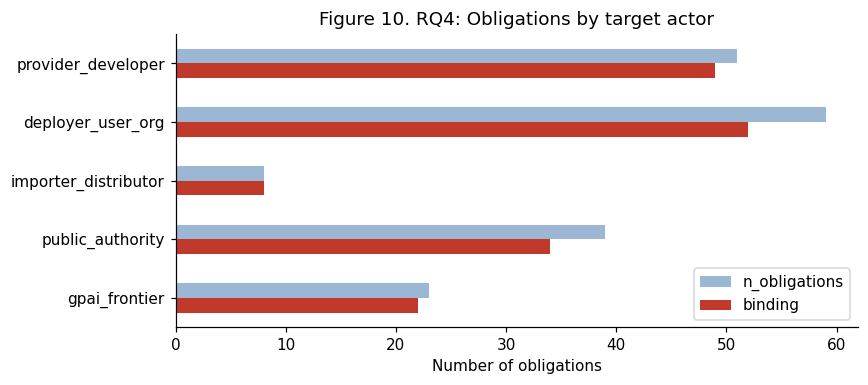

**Table 17. RQ4 - Share of operational/technical obligations by target actor**

,share_operational_technical
provider_developer,0.392
deployer_user_org,0.220
importer_distributor,0.250
public_authority,0.282
gpai_frontier,0.304


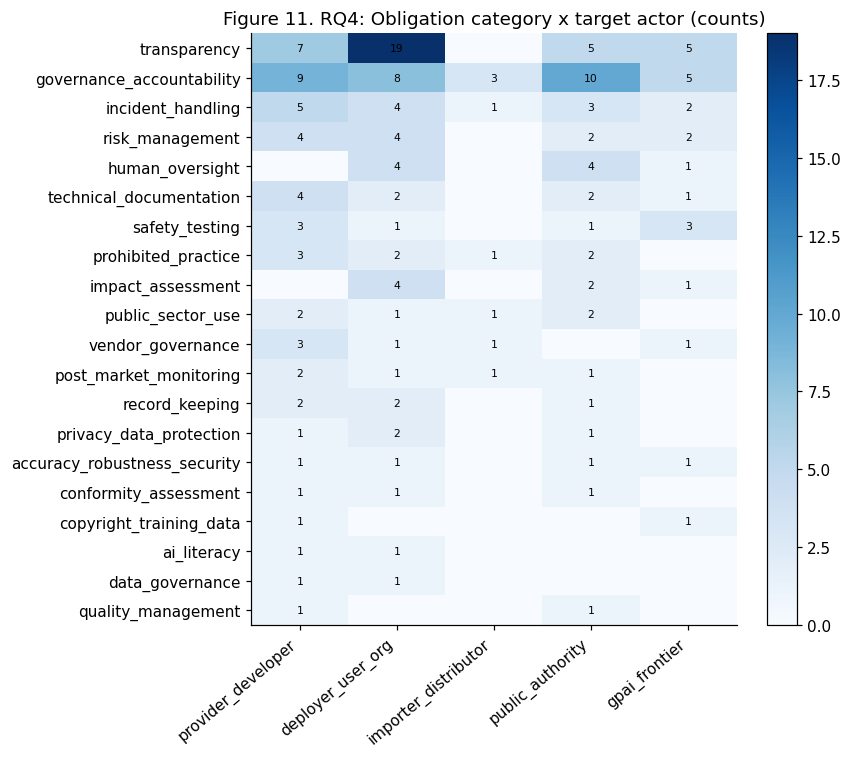

**Table 18. RQ4 - Obligation category x target actor (counts)**

,provider_developer,deployer_user_org,importer_distributor,public_authority,gpai_frontier
category,,,,,
transparency,7,19,0,5,5
governance_accountability,9,8,3,10,5
incident_handling,5,4,1,3,2
risk_management,4,4,0,2,2
human_oversight,0,4,0,4,1
technical_documentation,4,2,0,2,1
safety_testing,3,1,0,1,3
prohibited_practice,3,2,1,2,0
impact_assessment,0,4,0,2,1


**Table 19. RQ4 - Obligations per jurisdiction (top-1 share = 0.376; HHI = 0.184)**

,n_obligations,share
jurisdiction,,
eu,44,0.376
us-colorado,15,0.128
south-korea,9,0.077
uk,7,0.060
us,7,0.060
us-texas,7,0.060
singapore,6,0.051
us-new-york,5,0.043
us-california,5,0.043


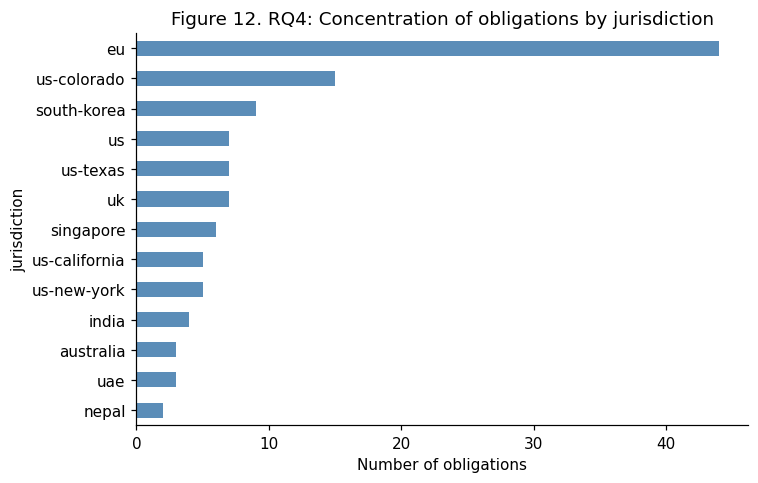

**Table 20. RQ4 - Implementation instruments (descriptive; n = 8)**

,slug,kind,status,source_tier,published_on,confidence_level
0,eu-ai-act-ai-generated-content-marking-code,code_of_practice,unverified,4,NaT,unavailable
1,eu-ai-act-gpai-code-of-practice,code_of_practice,published,2,2025-07-10,medium
2,eu-ai-act-guidelines-on-prohibited-practices,guidelines,published,2,2025-02-04,medium
3,eu-ai-act-high-risk-classification-guidelines,guidelines,unverified,4,NaT,unavailable
4,eu-ai-act-training-content-summary-template,template,unverified,4,NaT,unavailable
5,iso-iec-42001-2023,iso_work_item,published,1,2023-12-18,medium
6,iso-iec-42005-2025,iso_work_item,published,1,2025-01-01,medium
7,iso-iec-42006-2025,iso_work_item,published,1,2025-01-01,medium


**Table 21. RQ4 - Implementation instruments by kind and status**

status,published,unverified
kind,,
code_of_practice,1,1
guidelines,1,1
iso_work_item,3,0
template,0,1


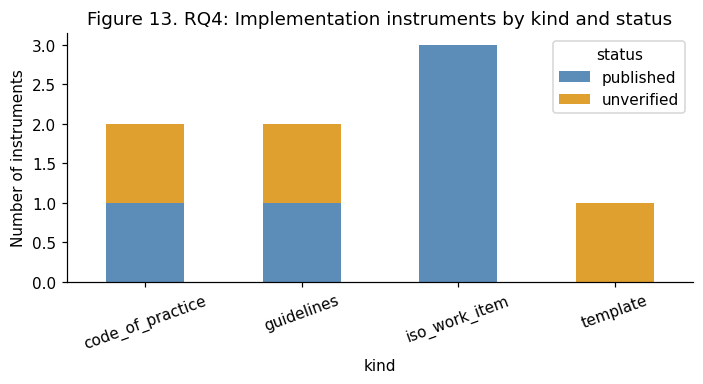

In [9]:
ACTORS = {
    "provider_developer": r"\b(providers?|developers?|manufacturers?|vendors?|suppliers?)\b",
    "deployer_user_org": r"\b(deployers?|operators?|users? of|organi[sz]ations?|businesses|companies|employers?|controllers?|processors?)\b",
    "importer_distributor": r"\b(importers?|distributors?|authori[sz]ed representatives?)\b",
    "public_authority": r"\b(public (authorit|bod|sector)\w*|government|agenc(y|ies)|regulators?|ministr\w+|authorit(y|ies))\b",
    "gpai_frontier": r"\b(general[- ]purpose|frontier|foundation model|systemic risk|high-impact)\b",
}
for a, rx in ACTORS.items():
    obl[f"actor_{a}"] = obl["obl_text"].str.contains(rx, flags=re.I, regex=True)
actor_cols = [f"actor_{a}" for a in ACTORS]
obl["no_actor_detected"] = ~obl[actor_cols].any(axis=1)

burden = pd.DataFrame({"n_obligations": obl[actor_cols].sum(),
                       "binding": obl.loc[obl["is_binding"], actor_cols].sum(),
                       "share_of_all": (obl[actor_cols].mean() * 100).round(1)})
burden.index = [i.replace("actor_", "") for i in burden.index]
show(burden, "Table 16. RQ4 - Obligations by target actor (an obligation can name several actors)", "t16_rq4_actor_burden")
ax = burden[["n_obligations", "binding"]].plot(kind="barh", figsize=(8, 3.6), color=["#9bb7d4", "#c0392b"])
ax.set_xlabel("Number of obligations"); ax.set_title("Figure 10. RQ4: Obligations by target actor"); ax.invert_yaxis(); plt.tight_layout()
savefig("fig10_rq4_actor_burden")

# actor x category (operational / technical measures)
OPERATIONAL = ["technical_documentation", "safety_testing", "record_keeping", "accuracy_robustness_security",
               "conformity_assessment", "post_market_monitoring", "quality_management", "data_governance", "incident_handling"]
obl["operational"] = obl["category"].isin(OPERATIONAL)
act_cat = {a.replace("actor_", ""): obl.loc[obl[a], "operational"].mean().round(3) for a in actor_cols}
act_tbl = pd.Series(act_cat, name="share_operational_technical").astype(float).round(3).to_frame()
show(act_tbl, "Table 17. RQ4 - Share of operational/technical obligations by target actor", "t17_rq4_operational_share")

heat = pd.DataFrame({a.replace("actor_", ""): obl.loc[obl[a]].groupby("category").size() for a in actor_cols}).fillna(0).astype(int)
heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(heat.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(heat.shape[1])); ax.set_xticklabels(heat.columns, rotation=40, ha="right")
ax.set_yticks(range(heat.shape[0])); ax.set_yticklabels(heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        if heat.values[i, j]:
            ax.text(j, i, heat.values[i, j], ha="center", va="center", fontsize=7)
ax.set_title("Figure 11. RQ4: Obligation category x target actor (counts)"); plt.colorbar(im); plt.tight_layout()
savefig("fig11_rq4_actor_category_heatmap")
show(heat, "Table 18. RQ4 - Obligation category x target actor (counts)", "t18_rq4_actor_category")

# obligations per policy by jurisdiction (burden concentration)
conc = obl["jurisdiction"].value_counts(normalize=True)
jur_tbl = pd.DataFrame({"n_obligations": obl["jurisdiction"].value_counts(), "share": conc.round(3)})
show(jur_tbl, f"Table 19. RQ4 - Obligations per jurisdiction (top-1 share = {conc.iloc[0]:.3f}; HHI = {(conc ** 2).sum():.3f})", "t19_rq4_obligations_per_jurisdiction")
jur_tbl["n_obligations"].sort_values().plot(kind="barh", figsize=(7, 4.5), color="#5b8db8")
plt.xlabel("Number of obligations"); plt.title("Figure 12. RQ4: Concentration of obligations by jurisdiction"); plt.tight_layout()
savefig("fig12_rq4_obligations_per_jurisdiction")

# implementation instruments (descriptive)
imp["published_on"] = pd.to_datetime(imp["published_on"], errors="coerce")
show(imp[["slug", "kind", "status", "source_tier", "published_on", "confidence_level"]],
     "Table 20. RQ4 - Implementation instruments (descriptive; n = 8)", "t20_rq4_implementation_instruments", index=False)
impc = imp.groupby(["kind", "status"]).size().unstack(fill_value=0)
show(impc, "Table 21. RQ4 - Implementation instruments by kind and status", "t21_rq4_implementation_kind_status")
impc.plot(kind="bar", stacked=True, figsize=(6.5, 3.6), color=["#5b8db8", "#e0a030"])
plt.ylabel("Number of instruments"); plt.title("Figure 13. RQ4: Implementation instruments by kind and status"); plt.xticks(rotation=20); plt.tight_layout()
savefig("fig13_rq4_implementation_instruments")